random change

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

In [2]:
# Read in text files with the filenames and labels 
def read_txt_files(path):

    rows = []

    with open(path, encoding='UTF-8') as f:
        
        for line in f:

            line = line.strip()

            filename = line.split(",")[0]

            labels = line.split(",")[1:]

            rows.append({'filename':filename, 'labels':labels})

        data = pd.DataFrame(rows)

        return data

test_data = read_txt_files('rover_image_classification/mer-labeled-data-set-v1.1.0/test-set-v1.1.0.txt')

train_data = read_txt_files('rover_image_classification/mer-labeled-data-set-v1.1.0/train-set-v1.1.0.txt')

val_data = read_txt_files('rover_image_classification/mer-labeled-data-set-v1.1.0/val-set-v1.1.0.txt')

In [3]:
# Around 30 rows in the train data are not in the images so will drop these rows doesnt seem to be the same in val and test data so will leave as is there
image_dir = Path('rover_image_classification/mer-labeled-data-set-v1.1.0/images')

folder_files = []
for f in image_dir.iterdir():

    folder_files.append(f.name)

folder_files = pd.DataFrame(folder_files,columns=['filename'])

In [4]:
drop_train_data = train_data[~train_data['filename'].isin(folder_files['filename'])].index

train_data.drop(drop_train_data,inplace=True)

In [5]:
# No missing files in these datasets
print(len(val_data[~val_data['filename'].isin(folder_files['filename'])]))
print(len(test_data[~test_data['filename'].isin(folder_files['filename'])]))

0
0


In [6]:
# Filtering the data to only contain the original images of the dataset
orig_train_data = train_data[train_data['filename'].str.endswith('img.jpg')].copy()
orig_test_data = test_data[test_data['filename'].str.endswith('img.jpg')].copy()
orig_val_data = val_data[val_data['filename'].str.endswith('img.jpg')].copy()

In [7]:
# Loading images and returning arrays of the image data on the original pictures
def load_images(path):

    image = Image.open(image_dir/path)

    return np.array(image)

orig_train_data['images'] = orig_train_data['filename'].apply(load_images)
orig_test_data['images'] = orig_test_data['filename'].apply(load_images)
orig_val_data['images'] = orig_val_data['filename'].apply(load_images)

In [8]:
# Concatenating all data into one df to perform analysis on all data
data = pd.concat([orig_train_data, orig_val_data, orig_test_data], ignore_index=True)

LABEL 

In [23]:
l = data["labels"].explode().str.strip().unique()

print(len(l))



25


In [10]:
data.head()

,filename,labels,images
0,1p128287181mrd0000p2303l2m1.img.jpg,"[ Soil, Spherules, Sky, Nearby Surface]","[[121, 139, 143, 137, 141, 140, 134, 133, 140,..."
1,1p128287268mrd0000p2303l2m1.img.jpg,"[ Rover Deck, Dunes/Ripples, Soil, Spherule...","[[62, 54, 48, 51, 59, 61, 54, 45, 45, 52, 60, ..."
2,1p128288415mrd0000p2303l2m1.img.jpg,"[ Rocks (misc), Dunes/Ripples, Soil, Spheru...","[[116, 135, 139, 133, 135, 134, 129, 129, 137,..."
3,1p128289213mrd0000p2303l2m1.img.jpg,"[ Soil, Spherules, Nearby Surface]","[[68, 55, 106, 97, 112, 123, 107, 106, 110, 10..."
4,1p129341281mrd0300p2376l2m1.img.jpg,"[ Rock Outcrops, Clasts, Rock (Linear Featur...","[[108, 125, 141, 147, 149, 147, 135, 120, 133,..."


In [12]:
label = data['labels'].explode()
labelcounter = label.value_counts()
print(labelcounter)


labels
Soil                         2891
Nearby Surface               2007
Rock Outcrops                1915
Clasts                       1676
Dunes/Ripples                1000
Sky                           955
Rock (Linear Features)        943
Distant Vista                 907
Spherules                     869
Float Rocks                   860
Rover Tracks                  301
Rover Parts                   301
Rocks (misc)                  249
Rover Deck                    222
Rock (Round Features)         219
Bright Soil                   122
Other Hardware                116
Soil Trench                    34
RAT Hole                       30
Artifacts                      28
Close-up Rock                  23
RAT Brushed Target             17
Pancam Calibration Target      14
Astronomy                      12
Arm Hardware                    4
Name: count, dtype: int64


<Axes: ylabel='labels'>

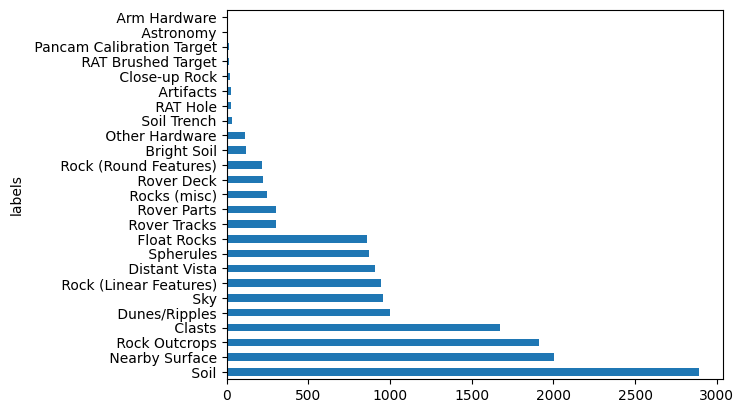

In [13]:
data['labels'].explode().value_counts().plot(kind='barh')

In [14]:
data['labelcounter'] = data['labels'].apply(len)
data['labelcounter'].describe()

count    3004.000000
mean        5.231358
std         1.309334
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        11.000000
Name: labelcounter, dtype: float64

<Axes: ylabel='labels'>

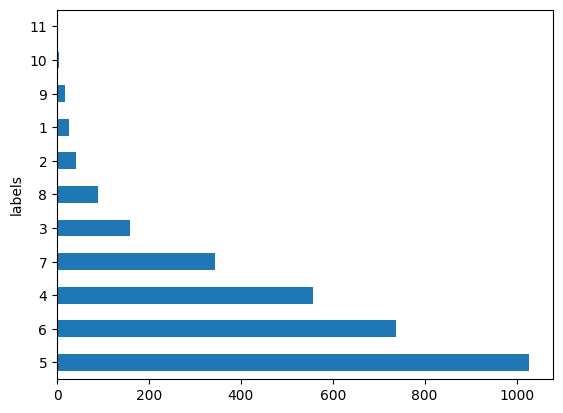

In [15]:
data['labels'].apply(len).value_counts().plot(kind='barh')

In [ ]:
data["labels"].isna().sum()

In [29]:
print(data["filename"].duplicated().sum())

0


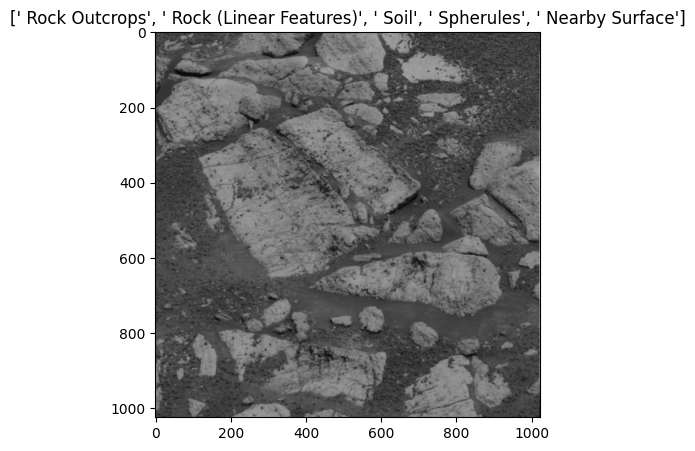

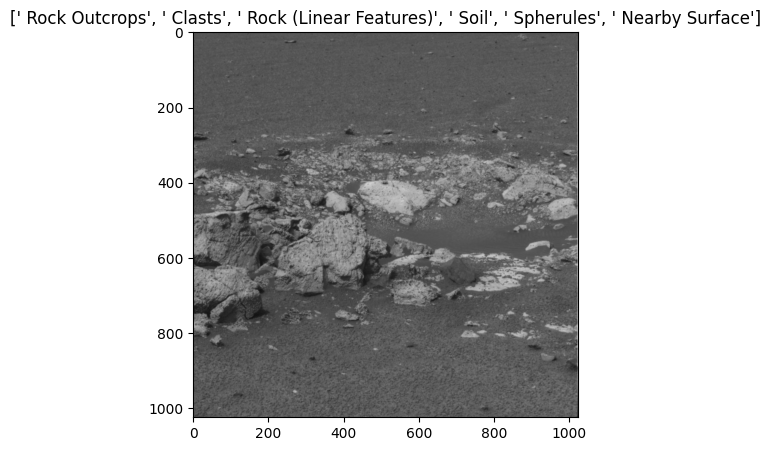

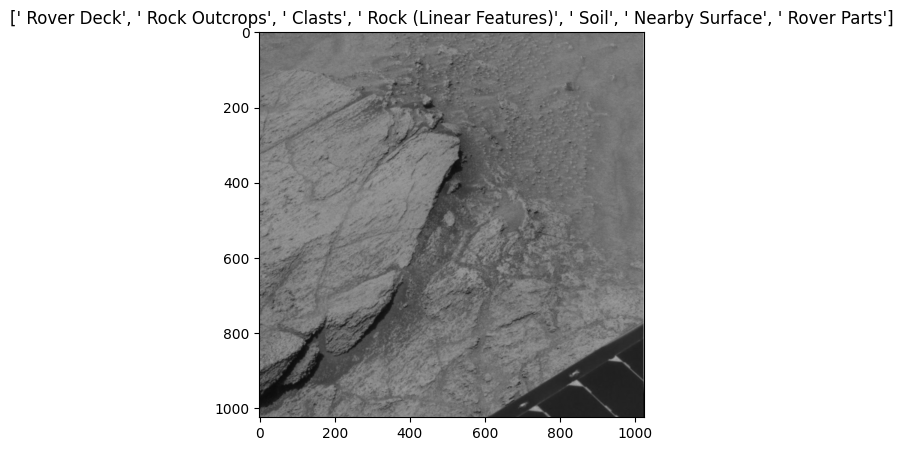

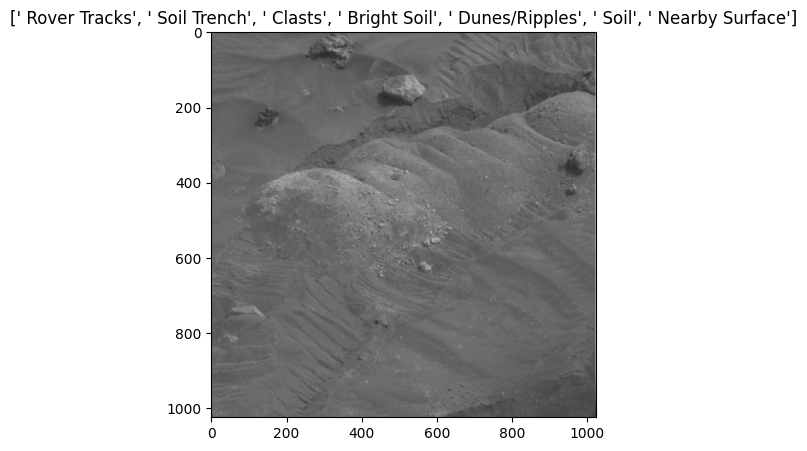

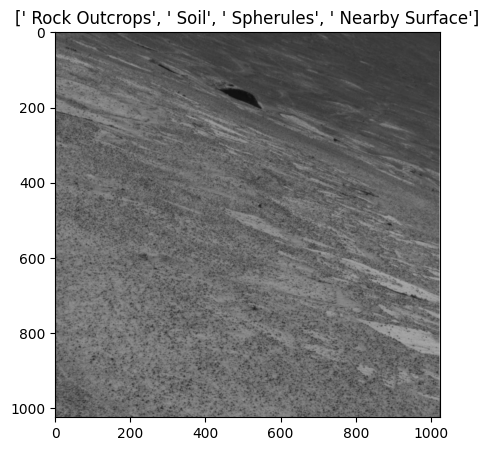

In [46]:
import matplotlib.pyplot as plt

image1 = data["images"].iloc[22]
labels1 = data["labels"].iloc[22]
plt.figure(figsize=(5,5))
plt.imshow(image1,cmap="gray")
plt.title(labels1)
plt.show()

image2 = data["images"].iloc[455]
labels2 = data["labels"].iloc[455]
plt.figure(figsize=(5,5))
plt.imshow(image2,cmap="gray")
plt.title(labels2)
plt.show()

image3 = data["images"].iloc[2201]
labels3 = data["labels"].iloc[2201]
plt.figure(figsize=(5,5))
plt.imshow(image3,cmap="gray")
plt.title(labels3)
plt.show()

image4 = data["images"].iloc[3000]
labels4 = data["labels"].iloc[3000]
plt.figure(figsize=(5,5))
plt.imshow(image4,cmap="gray")
plt.title(labels4)
plt.show()

image5 = data["images"].iloc[37]
labels5 = data["labels"].iloc[37]
plt.figure(figsize=(5,5))
plt.imshow(image5,cmap="gray")
plt.title(labels5)
plt.show()

In [47]:

counttrain = orig_train_data['labels'].explode().value_counts()

counttest = orig_test_data['labels'].explode().value_counts()
countval = orig_val_data['labels'].explode().value_counts()

In [51]:
print("Test:",counttest)

Test: labels
Soil                         714
Nearby Surface               496
Rock Outcrops                452
Clasts                       407
Spherules                    236
Dunes/Ripples                230
Sky                          229
Distant Vista                223
Rock (Linear Features)       221
Float Rocks                  215
Rover Tracks                 104
Rover Parts                   94
Rover Deck                    60
Rocks (misc)                  59
Other Hardware                43
Bright Soil                   38
Rock (Round Features)         38
Artifacts                      6
RAT Hole                       5
Close-up Rock                  5
RAT Brushed Target             4
Pancam Calibration Target      3
Soil Trench                    2
Astronomy                      2
Arm Hardware                   1
Name: count, dtype: int64


In [52]:
print("Train:",counttrain)

Train: labels
Soil                         1733
Nearby Surface               1206
Rock Outcrops                1184
Clasts                       1027
Dunes/Ripples                 616
Rock (Linear Features)        588
Sky                           572
Distant Vista                 541
Float Rocks                   508
Spherules                     486
Rover Parts                   171
Rover Tracks                  156
Rocks (misc)                  153
Rock (Round Features)         150
Rover Deck                    135
Bright Soil                    65
Other Hardware                 63
Soil Trench                    24
Artifacts                      19
RAT Hole                       19
Close-up Rock                  15
RAT Brushed Target             10
Astronomy                       9
Pancam Calibration Target       8
Arm Hardware                    2
Name: count, dtype: int64


In [53]:

print("Val:",countval)

Val: labels
Soil                         444
Nearby Surface               305
Rock Outcrops                279
Clasts                       242
Dunes/Ripples                154
Sky                          154
Spherules                    147
Distant Vista                143
Float Rocks                  137
Rock (Linear Features)       134
Rover Tracks                  41
Rocks (misc)                  37
Rover Parts                   36
Rock (Round Features)         31
Rover Deck                    27
Bright Soil                   19
Other Hardware                10
Soil Trench                    8
RAT Hole                       6
Pancam Calibration Target      3
RAT Brushed Target             3
Artifacts                      3
Close-up Rock                  3
Arm Hardware                   1
Astronomy                      1
Name: count, dtype: int64


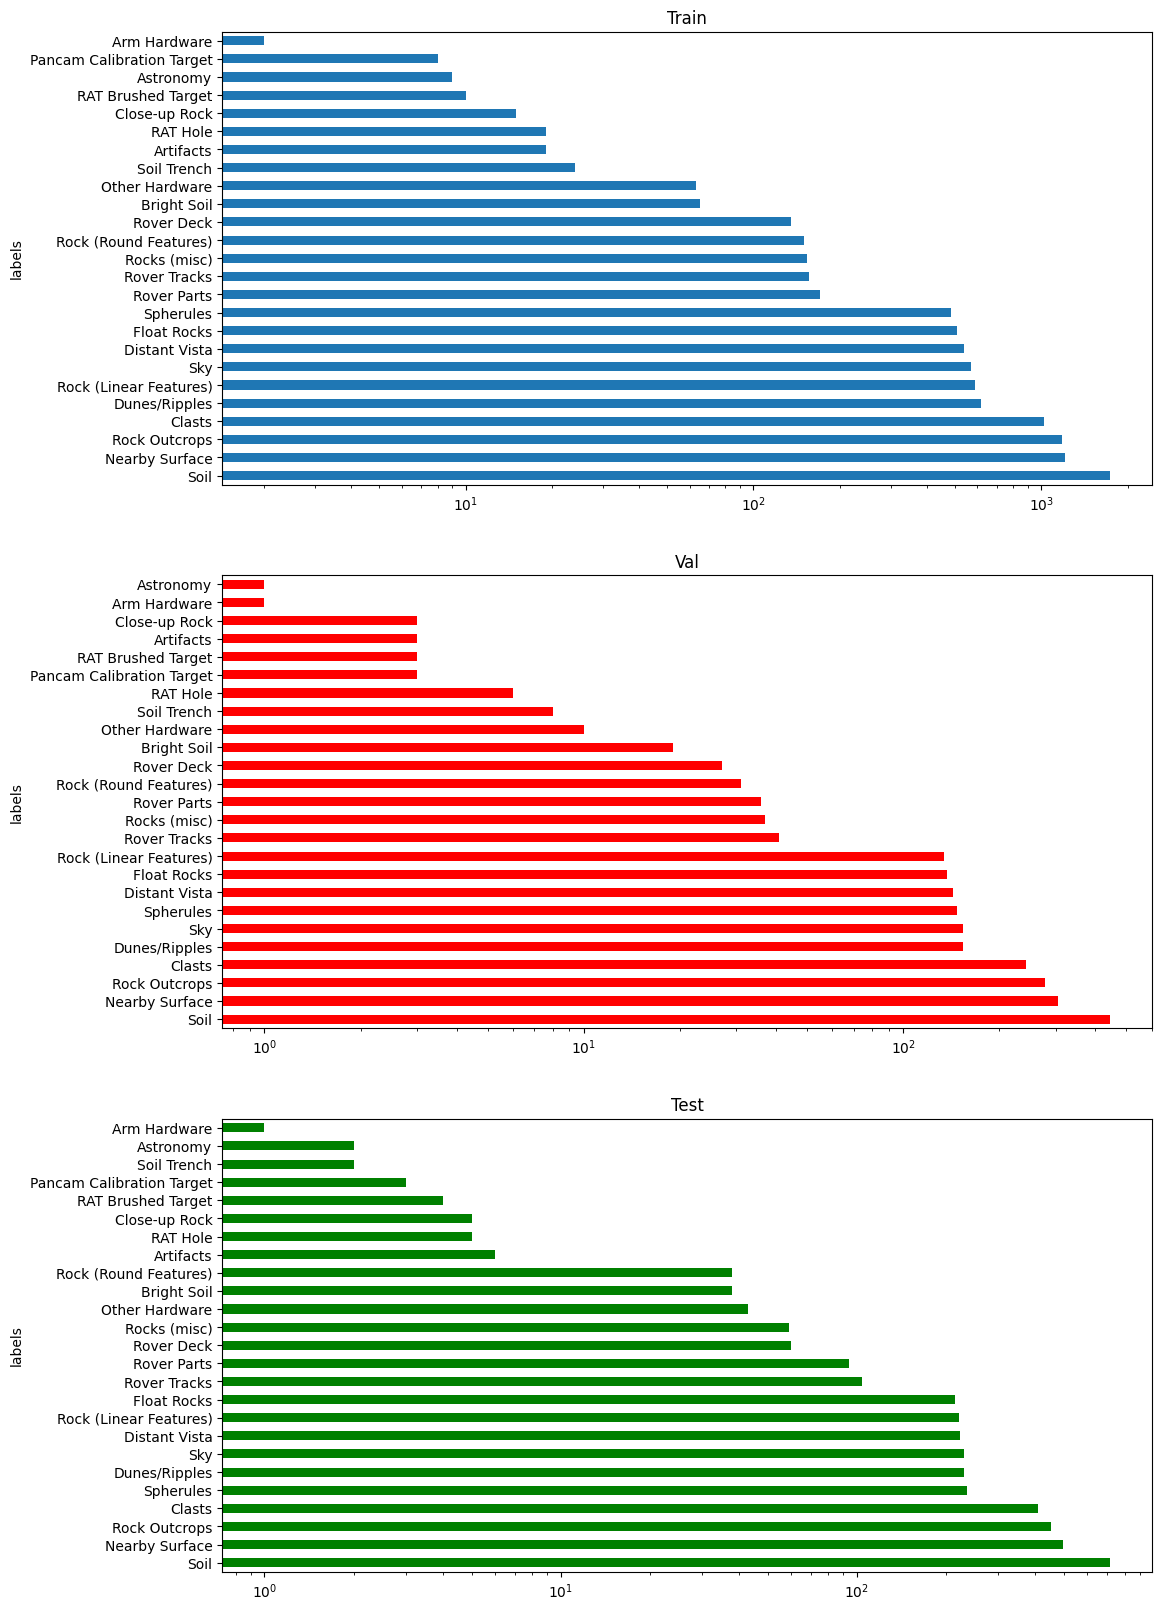

In [66]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3,1, figsize=(12,20))

orig_train_data['labels'].explode().str.strip().value_counts().plot(
    kind='barh', ax=axes[0],title='Train', logx=True)

orig_val_data['labels'].explode().str.strip().value_counts().plot(
    kind='barh', ax=axes[1], title='Val', logx=True, color = 'red')

orig_test_data['labels'].explode().str.strip().value_counts().plot(
    kind='barh',ax=axes[2], title='Test', logx=True, color = 'green')
plt.show()